# Phase 6 — Combination Validation

Implements Chapter 3, Section 3.7 and Chapter 4, Section 4.8 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"*.

The sequential selection in Phases 2, 4, and 5 is not guaranteed to find the same
combination as an exhaustive search over all 3 x 3 x 3 = 27 possible model x detector x
feature-selection-method pairings. Rather than assuming the sequential result is adequate,
or running the full 27-combination grid, a reduced robustness check is used: the
sequentially-selected combination is compared end-to-end against three alternatives, each
formed by substituting the second-best choice for exactly one component at a time.

This notebook reuses `dynamic_framework.run_dynamic_pipeline` -- the same core simulation
loop that Phase 7 will use, unchanged, for the final proposed framework (Chapter 4, Section
4.2's rationale for keeping shared logic in `src/`) -- to run all four combinations
end-to-end on the same synthetic drift stream used in Phases 4–5.

**The four combinations compared:**

| # | Model | Detector | Feature-selection method |
|---|---|---|---|
| Sequential (baseline) | Random Forest | ADWIN | RF Importance |
| Alt. model | XGBoost | ADWIN | RF Importance |
| Alt. detector | Random Forest | DDM | RF Importance |
| Alt. feature-selection | Random Forest | ADWIN | Correlation |

**Output:**
- `results/tables/phase6_combination_comparison.csv` — full metric suite per combination
- `results/figures/phase6_combination_comparison.png` — comparison figure
- `results/tables/phase6_artifacts.json` — the validated (or revised) combination, consumed by Phase 7

In [1]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/dissertation-project


In [2]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_utils as du
import models as mdl
import metrics as mt
import drift_detectors as dd
import feature_selection as fsel
import dynamic_framework as dyn

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load artefacts from Phases 2–5 and rebuild the synthetic drift stream

In [4]:
artifacts_p2 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase2_artifacts.json'))
artifacts_p3 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase3_artifacts.json'))
artifacts_p4 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase4_artifacts.json'))
artifacts_p5 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase5_artifacts.json'))

feature_cols = artifacts_p2['feature_cols']
target_col = artifacts_p2['target_col']
window_size = artifacts_p3['chosen_window_size']
top_k = artifacts_p5['top_k']

best_model = artifacts_p2['best_model']
second_best_model = artifacts_p2['second_best_model']
best_detector = artifacts_p4['best_detector']
second_best_detector = [d for d in artifacts_p4['ranking'] if d != best_detector][0]
best_fs_method = artifacts_p5['best_feature_selection_method']
second_best_fs_method = artifacts_p5['ranking'][1]

test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_test.csv'))
injection = dd.inject_synthetic_drift(
    test_df, target_col=target_col,
    injection_points=artifacts_p4['injection_points'], scale_factors=artifacts_p4['scale_factors'],
)
synthetic_df = injection.df

print('Sequential (best) choices:  ', best_model, '|', best_detector, '|', best_fs_method)
print('Second-best alternatives:   ', second_best_model, '|', second_best_detector, '|', second_best_fs_method)
print('Window length:', window_size, '| top_k:', top_k)

Sequential (best) choices:   random_forest | adwin | rf_importance
Second-best alternatives:    xgboost | ddm | correlation
Window length: 4000 | top_k: 6


## 2. Define and run the four combinations

Each combination is run end-to-end on the same synthetic stream using `dynamic_framework.run_dynamic_pipeline`, then summarised with the full metric suite via `dynamic_framework.summarize_result` (Chapter 3, Table 3.5).

In [5]:
COMBINATIONS = {
    'sequential': {'model': best_model, 'detector': best_detector, 'fs_method': best_fs_method},
    'alt_model': {'model': second_best_model, 'detector': best_detector, 'fs_method': best_fs_method},
    'alt_detector': {'model': best_model, 'detector': second_best_detector, 'fs_method': best_fs_method},
    'alt_fs_method': {'model': best_model, 'detector': best_detector, 'fs_method': second_best_fs_method},
}
COMBINATION_LABELS = {
    'sequential': 'Sequential (baseline)',
    'alt_model': f'Alt. model ({mdl.MODEL_DISPLAY_NAMES[second_best_model]})',
    'alt_detector': f'Alt. detector ({dd.DETECTOR_DISPLAY_NAMES[second_best_detector]})',
    'alt_fs_method': f'Alt. feature selection ({second_best_fs_method})',
}

results = {}
summaries = {}

for combo_name, combo in COMBINATIONS.items():
    print(f"Running '{combo_name}': {combo['model']} | {combo['detector']} | {combo['fs_method']} ...")
    result = dyn.run_dynamic_pipeline(
        synthetic_df, feature_cols, target_col,
        model_name=combo['model'], detector_name=combo['detector'], feature_selection_method=combo['fs_method'],
        window_size=window_size, top_k=top_k,
    )
    results[combo_name] = result
    summaries[combo_name] = dyn.summarize_result(result)
    print(f"  -> {result.n_retrains} retrains, MAE = {summaries[combo_name]['MAE']:.4f}, "
          f"runtime = {summaries[combo_name]['total_runtime_s']:.1f}s")

Running 'sequential': random_forest | adwin | rf_importance ...
  -> 3 retrains, MAE = 2.3842, runtime = 22.8s
Running 'alt_model': xgboost | adwin | rf_importance ...
  -> 2 retrains, MAE = 2.1508, runtime = 10.3s
Running 'alt_detector': random_forest | ddm | rf_importance ...
  -> 3 retrains, MAE = 2.2827, runtime = 16.6s
Running 'alt_fs_method': random_forest | adwin | correlation ...
  -> 3 retrains, MAE = 2.4217, runtime = 11.3s


## 3. Compare all four combinations

**Note on adaptation time**: the synthetic drift injection (Phase 4) applies a sustained multiplicative shift to the target, not a temporary blip -- so "recovery to the pre-drift error level" is not necessarily achievable even for a well-adapted model, since the post-drift regime's error scale is itself different. Where `mean_adaptation_time_rows` is NaN below, no drift event recovered to within tolerance of its pre-drift baseline before the next drift point or the end of the stream -- this is reported as-is rather than hidden, and is a property of this injection design, not a pipeline failure.

In [6]:
comparison_rows = []
for combo_name, summary in summaries.items():
    comparison_rows.append({
        'combination': combo_name,
        'label': COMBINATION_LABELS[combo_name],
        **{k: v for k, v in COMBINATIONS[combo_name].items()},
        **summary,
    })

comparison_df = pd.DataFrame(comparison_rows)
display_cols = ['label', 'MAE', 'RMSE', 'MAPE', 'Penalised_MAE', 'n_drift_events', 'n_retrains',
                 'mean_feature_stability_index', 'feature_switch_rate', 'mean_adaptation_time_rows',
                 'total_runtime_s']
comparison_df[display_cols]

,label,MAE,RMSE,MAPE,Penalised_MAE,n_drift_events,n_retrains,mean_feature_stability_index,feature_switch_rate,mean_adaptation_time_rows,total_runtime_s
0,Sequential (baseline),2.384248,3.174314,39.105291,3.080857,3,3,0.523810,0.666667,NaN,22.784490
1,Alt. model (XGBoost),2.150848,2.931723,36.639342,2.732744,2,2,0.333333,0.500000,NaN,10.262104
2,Alt. detector (DDM),2.282710,2.982234,36.880406,2.997963,3,3,0.714286,0.666667,0.0,16.648436
3,Alt. feature selection (correlation),2.421744,3.224865,39.524102,3.134509,3,3,0.500000,0.666667,NaN,11.339441


## 4. Visualise the comparison

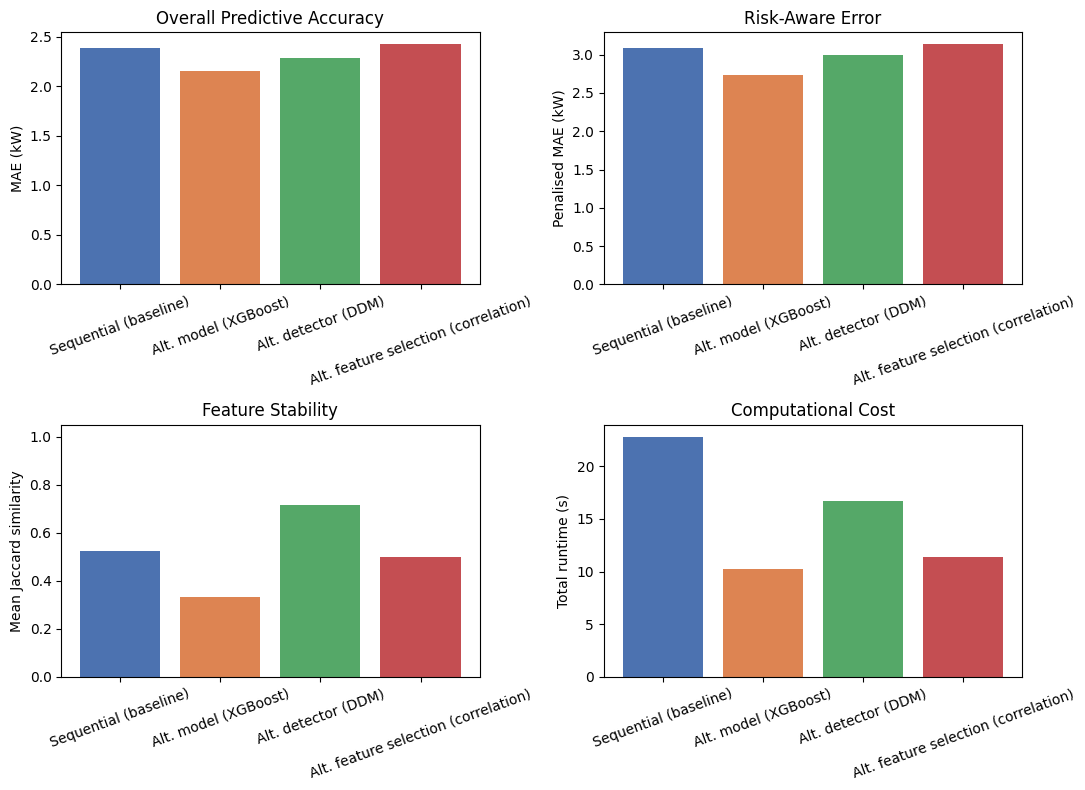

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase6_combination_comparison.png


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

axes[0, 0].bar(comparison_df['label'], comparison_df['MAE'], color=colors)
axes[0, 0].set_ylabel('MAE (kW)')
axes[0, 0].set_title('Overall Predictive Accuracy')
axes[0, 0].tick_params(axis='x', rotation=20)

axes[0, 1].bar(comparison_df['label'], comparison_df['Penalised_MAE'], color=colors)
axes[0, 1].set_ylabel('Penalised MAE (kW)')
axes[0, 1].set_title('Risk-Aware Error')
axes[0, 1].tick_params(axis='x', rotation=20)

axes[1, 0].bar(comparison_df['label'], comparison_df['mean_feature_stability_index'], color=colors)
axes[1, 0].set_ylabel('Mean Jaccard similarity')
axes[1, 0].set_title('Feature Stability')
axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].tick_params(axis='x', rotation=20)

axes[1, 1].bar(comparison_df['label'], comparison_df['total_runtime_s'], color=colors)
axes[1, 1].set_ylabel('Total runtime (s)')
axes[1, 1].set_title('Computational Cost')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase6_combination_comparison.png')
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150)
plt.show()
print('Saved figure to', fig_path)

## 5. Decide: retain the sequential combination, or adopt an alternative?

Consistent with Chapter 3, Section 3.7: if no substitution produces a **materially better** result than the sequentially-selected combination, the sequential design is retained; if a substitution performs materially better, that combination is adopted instead. "Materially better" is defined here as more than a 5% relative reduction in MAE -- an explicit, pre-specified threshold, rather than adopting any alternative that happens to edge out the baseline by a statistically meaningless margin.

In [8]:
MATERIAL_IMPROVEMENT_THRESHOLD = 0.05  # 5% relative MAE reduction

sequential_mae = comparison_df.loc[comparison_df['combination'] == 'sequential', 'MAE'].iloc[0]
comparison_df['relative_mae_change'] = (comparison_df['MAE'] - sequential_mae) / sequential_mae

best_row = comparison_df.loc[comparison_df['MAE'].idxmin()]
improvement = -best_row['relative_mae_change']  # positive = improvement over sequential

print(comparison_df[['label', 'MAE', 'relative_mae_change']].to_string(index=False))
print()

if best_row['combination'] != 'sequential' and improvement > MATERIAL_IMPROVEMENT_THRESHOLD:
    final_combination = {
        'model': best_row['model'], 'detector': best_row['detector'], 'fs_method': best_row['fs_method'],
    }
    decision = 'revised'
    print(f"DECISION: '{best_row['label']}' improves on the sequential combination by "
          f"{improvement:.1%}, exceeding the {MATERIAL_IMPROVEMENT_THRESHOLD:.0%} threshold.")
    print('The sequential design is REVISED in favour of this combination.')
else:
    final_combination = COMBINATIONS['sequential']
    decision = 'retained'
    print(f"DECISION: no alternative improves on the sequential combination by more than "
          f"{MATERIAL_IMPROVEMENT_THRESHOLD:.0%}.")
    print('The sequential design is RETAINED as the proposed framework\'s configuration.')

print()
print('Final combination for Phase 7:', final_combination)

                               label      MAE  relative_mae_change
               Sequential (baseline) 2.384248             0.000000
                Alt. model (XGBoost) 2.150848            -0.097893
                 Alt. detector (DDM) 2.282710            -0.042587
Alt. feature selection (correlation) 2.421744             0.015727

DECISION: 'Alt. model (XGBoost)' improves on the sequential combination by 9.8%, exceeding the 5% threshold.
The sequential design is REVISED in favour of this combination.

Final combination for Phase 7: {'model': 'xgboost', 'detector': 'adwin', 'fs_method': 'rf_importance'}


## 6. Persist artefacts for Phase 7

In [9]:
comparison_path = os.path.join(PROJECT_ROOT, 'results/tables/phase6_combination_comparison.csv')
comparison_df.to_csv(comparison_path, index=False)

artifacts = {
    'combinations_tested': COMBINATIONS,
    'decision': decision,
    'material_improvement_threshold': MATERIAL_IMPROVEMENT_THRESHOLD,
    'final_combination': final_combination,
}
artifacts_path = os.path.join(PROJECT_ROOT, 'results/tables/phase6_artifacts.json')
mdl.save_artifacts(artifacts, artifacts_path)

print('Saved comparison table to', comparison_path)
print('Saved artefacts to', artifacts_path)
print()
print(artifacts)

Saved comparison table to /content/drive/MyDrive/dissertation-project/results/tables/phase6_combination_comparison.csv
Saved artefacts to /content/drive/MyDrive/dissertation-project/results/tables/phase6_artifacts.json

{'combinations_tested': {'sequential': {'model': 'random_forest', 'detector': 'adwin', 'fs_method': 'rf_importance'}, 'alt_model': {'model': 'xgboost', 'detector': 'adwin', 'fs_method': 'rf_importance'}, 'alt_detector': {'model': 'random_forest', 'detector': 'ddm', 'fs_method': 'rf_importance'}, 'alt_fs_method': {'model': 'random_forest', 'detector': 'adwin', 'fs_method': 'correlation'}}, 'decision': 'revised', 'material_improvement_threshold': 0.05, 'final_combination': {'model': 'xgboost', 'detector': 'adwin', 'fs_method': 'rf_importance'}}


## Summary

This notebook implements Chapter 3, Section 3.7 and Chapter 4, Section 4.8. Rather than either assuming the sequentially-selected combination is optimal or running an exhaustive 27-combination search, three targeted alternatives were run end-to-end using the same pipeline that Phase 7 will use for the final framework. The decision to retain or revise the sequential combination is made against a pre-specified, explicit threshold rather than by eye, and the validated combination is carried forward as a fixed artefact into Phase 7.